<h3> How to use ImageOverlay</h3>

Raster images can be combined with maps having spatial references for placing them
Example


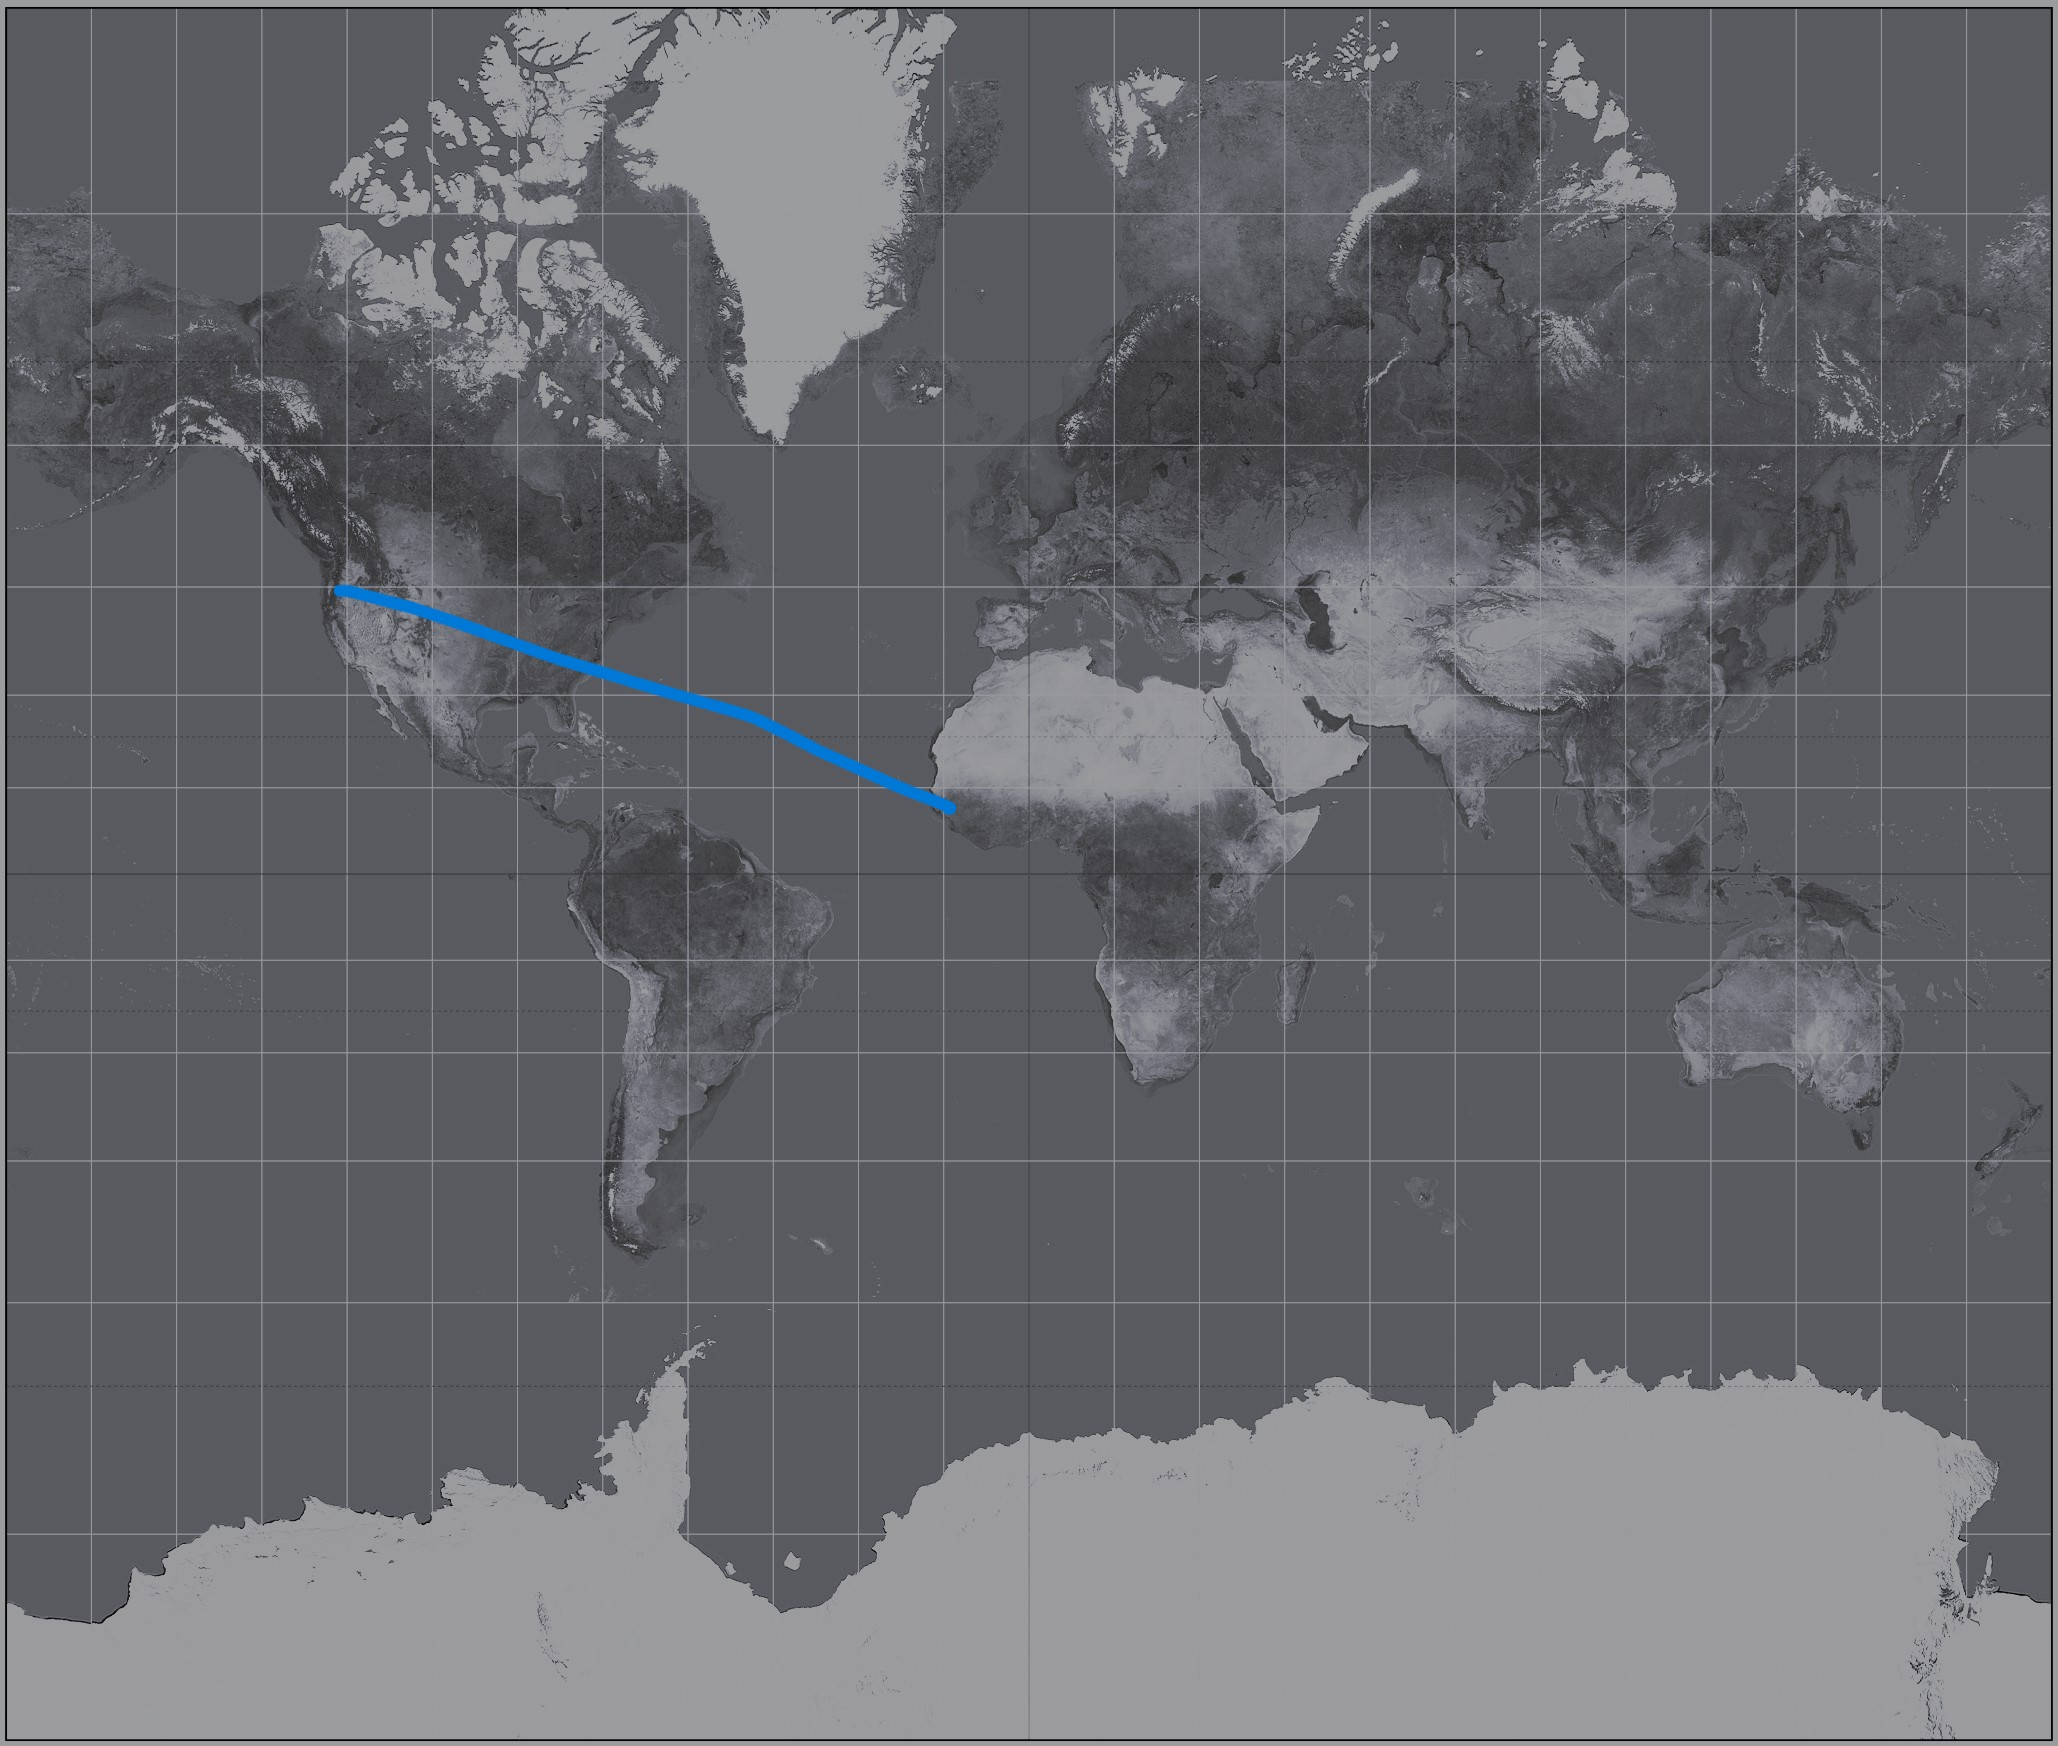

In [2]:
import os
import folium

m = folium.Map([37, 0], zoom_start=1)
merc = "Mercator_projection_SW.jpg"


if not os.path.isfile(merc):
    print(f"Could not find {merc}")
else:
    img = folium.raster_layers.ImageOverlay(
        name="Mercator projection SW",
        image=merc,
        bounds=[[-82, -180], [82, 180]],
        opacity=1,
        interactive=True,
        cross_origin=False,
        zindex=1,
    )

    folium.Popup("I am an image").add_to(img)

    img.add_to(m)
    folium.LayerControl().add_to(m)

m

A few remarks:

* Note that your image has to be in Mercator projection format.

  The image we've used is based on https://en.wikipedia.org/wiki/File:Mercator_projection_SW.jpg ; that you can find in wikipedia's article on Mercator Projection (https://en.wikipedia.org/wiki/Mercator_projection).


You can also provide simply URL. In this case, the image will not be embedded in folium's output.

In [3]:
m = folium.Map([37, 0], zoom_start=1, tiles="cartodb positron")

folium.raster_layers.ImageOverlay(
    image="https://upload.wikimedia.org/wikipedia/commons/f/f4/Mercator_projection_SW.jpg",
    name="I am a jpeg",
    bounds=[[-82, -180], [82, 180]],
    opacity=1,
    interactive=False,
    cross_origin=False,
    zindex=1,
    alt="Wikipedia File:Mercator projection SW.jpg",
).add_to(m)

folium.LayerControl().add_to(m)


m

This works exactly the same way if you want to put a JPG instead of a PNG.

Now you may wish to create your own image, based on another python computation.
For this, you'll need to have numpy installed on your machine.

Let's creater an image to draw a rectangle in the bounds `[[0, -60], [60, 60]]`.

In [9]:
import numpy as np

image = np.zeros((61, 61))
image[0, :] = 1.0
image[60, :] = 1.0
image[:, 0] = 1.0
image[:, 60] = 1.0

We can draw it on the map in using:


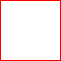

In [10]:
m = folium.Map([37, 0], zoom_start=2)

folium.raster_layers.ImageOverlay(
    image=image,
    bounds=[[0, -60], [60, 60]],
    colormap=lambda x: (1, 0, 0, x),
).add_to(m)

m